# Model Evaluation, Imbalanced Data, Thresholds, and Calibration

> Choose metrics around error costs and investigate more than overall accuracy.

**Track:** Machine Learning Roadmap · **Language:** English

## Learning goals
- Interpret precision, recall, F1, specificity, ROC-AUC, and PR-AUC.
- See why a majority-class classifier can have high accuracy and no practical value.
- Adjust decision thresholds on validation data and inspect probability calibration.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, ConfusionMatrixDisplay,
                             PrecisionRecallDisplay, RocCurveDisplay)

X, y = make_classification(n_samples=2200, n_features=16, n_informative=6, weights=[.97,.03], class_sep=1.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.25, stratify=y, random_state=42)
model = RandomForestClassifier(n_estimators=180, class_weight="balanced", min_samples_leaf=3, random_state=42, n_jobs=1).fit(X_train, y_train)
prob = model.predict_proba(X_test)[:,1]
pred = (prob >= .5).astype(int)
print({"positive_rate":round(y_test.mean(),3),"accuracy":round(accuracy_score(y_test,pred),3),"precision":round(precision_score(y_test,pred,zero_division=0),3),"recall":round(recall_score(y_test,pred,zero_division=0),3),"F1":round(f1_score(y_test,pred,zero_division=0),3),"ROC-AUC":round(roc_auc_score(y_test,prob),3),"PR-AUC/AP":round(average_precision_score(y_test,prob),3)})

{'positive_rate': np.float64(0.035), 'accuracy': 0.969, 'precision': 1.0, 'recall': 0.105, 'F1': 0.19, 'ROC-AUC': 0.97, 'PR-AUC/AP': 0.646}


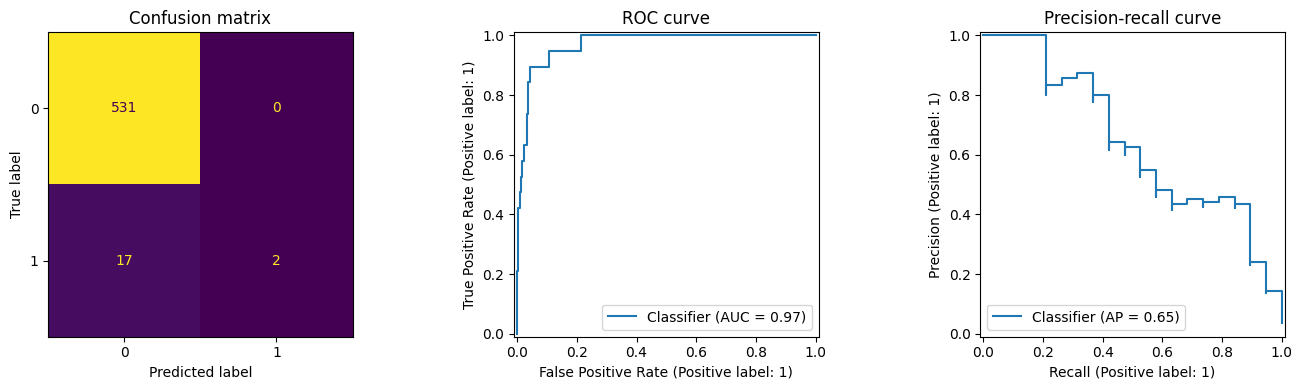

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=axes[0], colorbar=False)
RocCurveDisplay.from_predictions(y_test, prob, ax=axes[1])
PrecisionRecallDisplay.from_predictions(y_test, prob, ax=axes[2])
axes[0].set_title("Confusion matrix")
axes[1].set_title("ROC curve")
axes[2].set_title("Precision-recall curve")
plt.tight_layout()

## Why accuracy can mislead
If only 1% of events are positive, predicting “negative” for everyone achieves 99% accuracy, but recall for the event class is zero. For rare events, PR-AUC and the operating point at a meaningful precision/recall trade-off may be more informative. Always compare with the prevalence baseline.

In [3]:
from sklearn.metrics import precision_recall_curve
thresholds = [.02, .05, .1, .2, .5]
rows=[]
for t in thresholds:
    p = (prob >= t).astype(int)
    rows.append({"threshold":t,"predicted_positive_rate":p.mean(),"precision":precision_score(y_test,p,zero_division=0),"recall":recall_score(y_test,p,zero_division=0),"f1":f1_score(y_test,p,zero_division=0)})
display(pd.DataFrame(rows).round(3))

,threshold,predicted_positive_rate,precision,recall,f1
0,0.02,0.584,0.059,1.000,0.112
1,0.05,0.304,0.114,1.000,0.204
2,0.10,0.127,0.243,0.895,0.382
3,0.20,0.044,0.458,0.579,0.512
4,0.50,0.004,1.000,0.105,0.190


## Calibration and metric selection
A calibrated score of 0.8 should correspond to roughly 80% positives among comparable predictions. Good ranking (AUC) does not guarantee calibration. Use calibration plots / Brier score when probabilities drive decisions or planning. Threshold selection should happen on validation data and reflect capacity and error costs—not on a final test set.

## Practice
Imagine outreach can handle only 5% of customers. What would you inspect to choose a threshold? Explain why class weights or resampling must be applied only inside training folds.